In [17]:
from epyt_flow import utils
import matplotlib.pyplot as plt
import numpy as np
import utils as functions
import simulate
import torch
import wds_utils
from functools import partial
import model.semi_lagrangian_model_wrapper as SLMPNN

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
inp_file = 'networks/l_town_no_tanks.inp'
# inp_file = f'{inp_file_source[:-4]}_inline_removed.inp'

# Remove the nodes that have exactly two neighbors, those nodes 
# can be modeled as a single pipe when their demands are distributed 
# to their neighbors to maintain the same flow patterns
# wds_utils.remove_inline_nodes(inp_file_source, inp_file)
# wds_utils.convert_to_injection_nodes(
#     inp_file, ['n300', 'n115'], inp_file
# )
sources_at = ['R1', 'R2']
interesting_nodes = ['n21', 'n252']

N_SECONDS = utils.to_seconds(hours=12)
HYDRAULIC_STEP = 1 * 60
QUALITY_TIMESTEP = HYDRAULIC_STEP
PATTERN_STEP = HYDRAULIC_STEP
steps_per_pattern = int(PATTERN_STEP / HYDRAULIC_STEP)
topology = functions.read_inp(inp_file)

'L-Town Metric Graph'

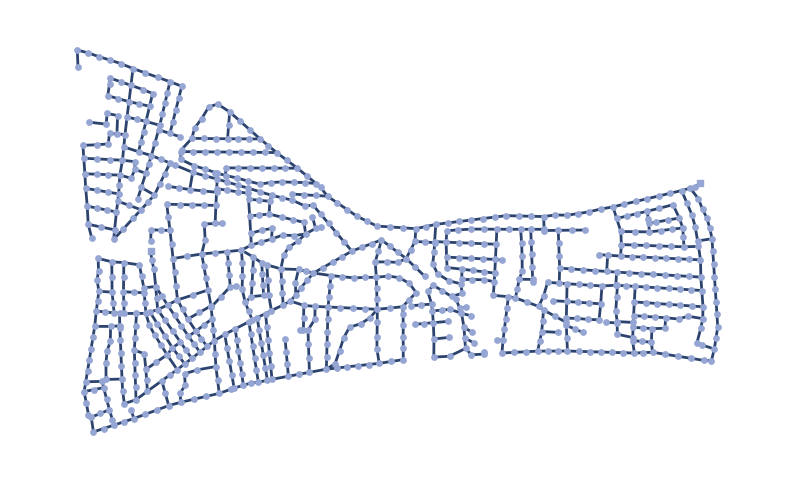

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))
_ = functions.plot_graph_from_topology(topology, ax=ax, node_size=15, labels=False, width=2)
'L-Town Metric Graph'

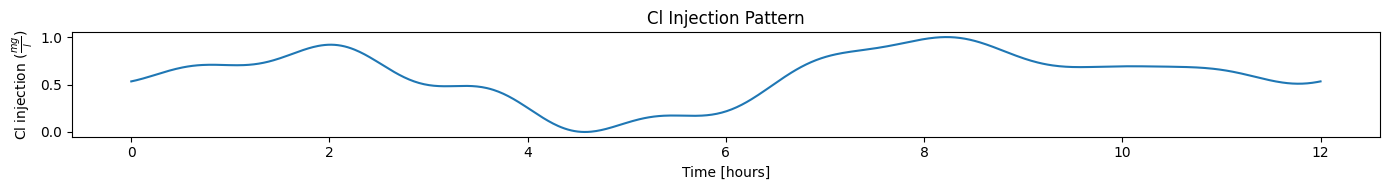

In [20]:
pattern_length = N_SECONDS // HYDRAULIC_STEP
seed = 42
from experiments.random_hydraulics_dataset import generate_injection_pattern
pattern = generate_injection_pattern(pattern_length, seed=seed)
# pattern = np.linspace(0, 2., pattern_length)# * 0 + 1
ts = np.linspace(0, N_SECONDS, pattern_length) / 60 / 60
plt.figure(figsize=(14, 2), tight_layout=True)
plt.plot(ts, pattern)
plt.title('Cl Injection Pattern');plt.xlabel('Time [hours]');_=plt.ylabel('Cl injection ($\\frac{mg}{l}$)')

In [21]:
from epyt.epanet import ToolkitConstants

graph_data = simulate.inp_to_graph_data(inp_file, pattern, sources_at, N_SECONDS, HYDRAULIC_STEP, QUALITY_TIMESTEP, PATTERN_STEP, f_msx_in='networks/ltown.msx', source_type=ToolkitConstants.EN_SETPOINT)
topo =  graph_data['topology']

Running EPANET ...


EPANET Error: WARNING: System hydraulically unbalanced.
/home/luca/.miniconda3/envs/wquality/lib/python3.9/site-packages/epyt_flow/simulation/scenario_simulator.py, line 2604: error_code = self.epanet_api.get_last_error_code()
EPANET Error: WARNING: System hydraulically unbalanced.
/home/luca/.miniconda3/envs/wquality/lib/python3.9/site-packages/epyt_flow/simulation/scenario_simulator.py, line 2604: error_code = self.epanet_api.get_last_error_code()


EPANET Error: WARNING: System hydraulically unbalanced.
/home/luca/.miniconda3/envs/wquality/lib/python3.9/site-packages/epyt_flow/simulation/scenario_simulator.py, line 2604: error_code = self.epanet_api.get_last_error_code()


















Time steps: 100%|#########9| 720/721 [00:14<00:00, 48.49it/s]


Running EPANET-MSX ...





































































Time steps: 100%|#########9| 720/721 [00:07<00:00, 99.56it/s]


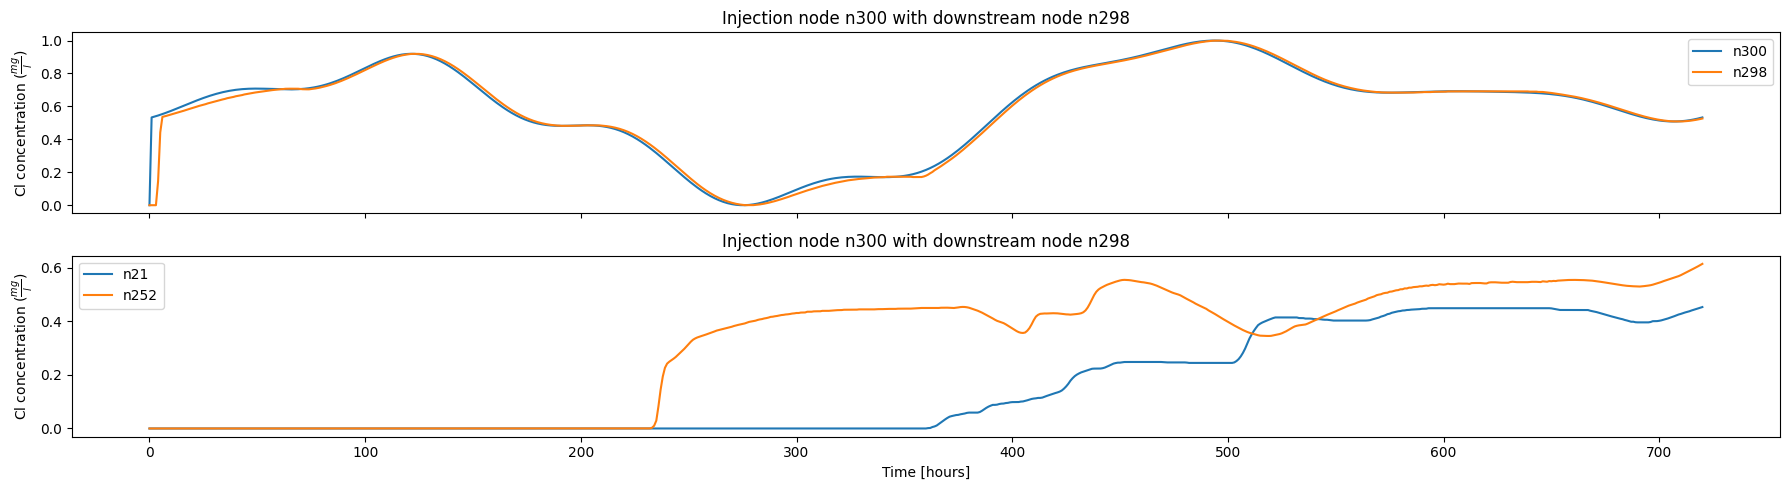

In [22]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 5), tight_layout=True, sharex=True)
ax1.set_title('Injection node n300 with downstream node n298')
_ = ax1.plot(graph_data['epanet_result'][functions.get_node_index(topo, ['R1', 'n298'])].T, label=['n300', 'n298'])
ax1.legend()
ax2.set_title('Injection node n300 with downstream node n298')
_ = ax2.plot(graph_data['epanet_result'][functions.get_node_index(topo, interesting_nodes)].T, label=interesting_nodes)
ax2.legend(); ax2.set_xlabel('Time [hours]'); ax1.set_ylabel('Cl concentration ($\\frac{mg}{l}$)'); _ = ax2.set_ylabel('Cl concentration ($\\frac{mg}{l}$)')

In [23]:
cT, Tau = 1, 700
time = cT + Tau
s = cT
device = 'cpu' # 'cuda' if torch.cuda.is_available() else 'cpu'

In [26]:
pred, edge_passes, _, agg_time, aggs_all = SLMPNN.semi_lagrangian_mpnn(
    graph_data['epanet_result'][:,:cT], graph_data['flow_field'], graph_data['edge_index'], graph_data['edge_lengths'], 
    output_times=[(cT+Tau) * HYDRAULIC_STEP], dt=HYDRAULIC_STEP, nsteps=Tau, edge_capacities=graph_data['edge_diameter'],
    control_indices=graph_data['boundary_index'], control_inputs=graph_data['boundary_values'],
    interpolation='bilinear', max_msg_passing_rounds=1000, device=device
)

  0%|          | 0/100 [00:00<?, ?it/s]

70


/home/luca/.miniconda3/envs/wquality/lib/python3.9/site-packages/networkx/drawing/nx_pylab.py:437: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  node_collection = ax.scatter(


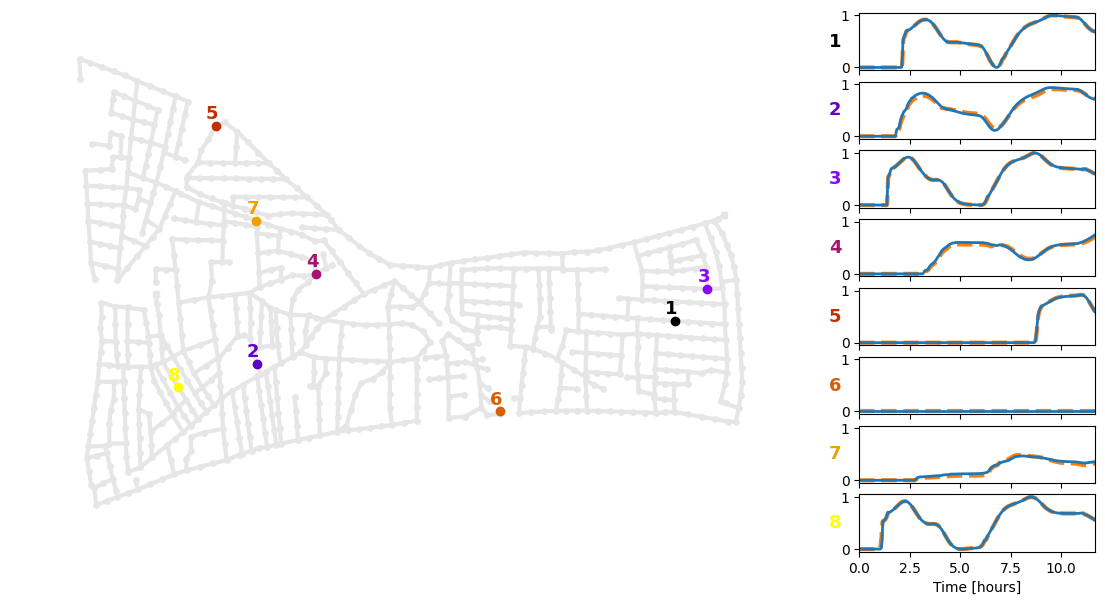

In [28]:
fig, ax = plt.subplot_mosaic(
    'WWW0\nWWW1\nWWW2\nWWW3\nWWW4\nWWW5\nWWW6\nWWW7',
    figsize=(14, 7)
)

pos = topology.query_node_attribute('coordinates')

n = 8
plot_nodes = np.random.RandomState(32).choice(topology.node_name_list, size=n)#[:6]
colors = plt.cm.gnuplot(np.linspace(0, 1, n))
lg = (0.9, 0.9, 0.9, 1.0)
c_it = iter(colors)

functions.plot_graph_from_topology(
    topo, node_colors=lg, edge_colors=lg, ax=ax['W'], node_size=15, width=3
)

gt_data = graph_data['epanet_result'][:,:cT+Tau]

ts = np.linspace(0, (cT+Tau)*HYDRAULIC_STEP+0.1, pred.shape[1]) / 60 / 60

for i, node in enumerate(plot_nodes):
    interesting_node_idx = functions.get_node_index(topo, node)[0]
    ax[str(i)].plot(ts, gt_data[interesting_node_idx], linestyle='--', linewidth=3, color='C1')
    ax[str(i)].plot(ts, pred[interesting_node_idx], linestyle='-', linewidth=2, color='C0')
    ax[str(i)].set_xlim(min(ts), max(ts))
    ax[str(i)].set_ylim(-0.05, 1.05)
    ax[str(i)].set_ylabel(i+1, rotation=0, fontdict={'weight':'bold', 'fontsize':13, 'color' : colors[i]}, va='center')#'$\\frac{mg}{l}$', rotation=0, va='center')
    ax['W'].text(*np.add(pos[node], 10), i+1, fontdict={'weight':'bold', 'fontsize':13, 'color' : colors[i]}, va='bottom', ha='right')
    ax['W'].scatter(*pos[node], c=[colors[i]], zorder=2)
    if i < n-1:
        ax[str(i)].set_xticklabels([])
    else:
        ax[str(i)].set_xlabel('Time [hours]')

In [29]:
import model.advection_model_mp

# Activate auxiliary outputs
model.advection_model_mp.DEBUG = True

pred, edge_passes, _, agg_time, aggs_all = SLMPNN.semi_lagrangian_mpnn(
    graph_data['epanet_result'][:,:cT], graph_data['flow_field'], graph_data['edge_index'], graph_data['edge_lengths'], 
    output_times=[Tau * HYDRAULIC_STEP], dt=HYDRAULIC_STEP, nsteps=Tau, edge_capacities=graph_data['edge_diameter'],
    control_indices=graph_data['boundary_index'], control_inputs=graph_data['boundary_values'],
    interpolation='bilinear', max_msg_passing_rounds=1000, device=device
)

  0%|          | 0/100 [00:00<?, ?it/s]

70


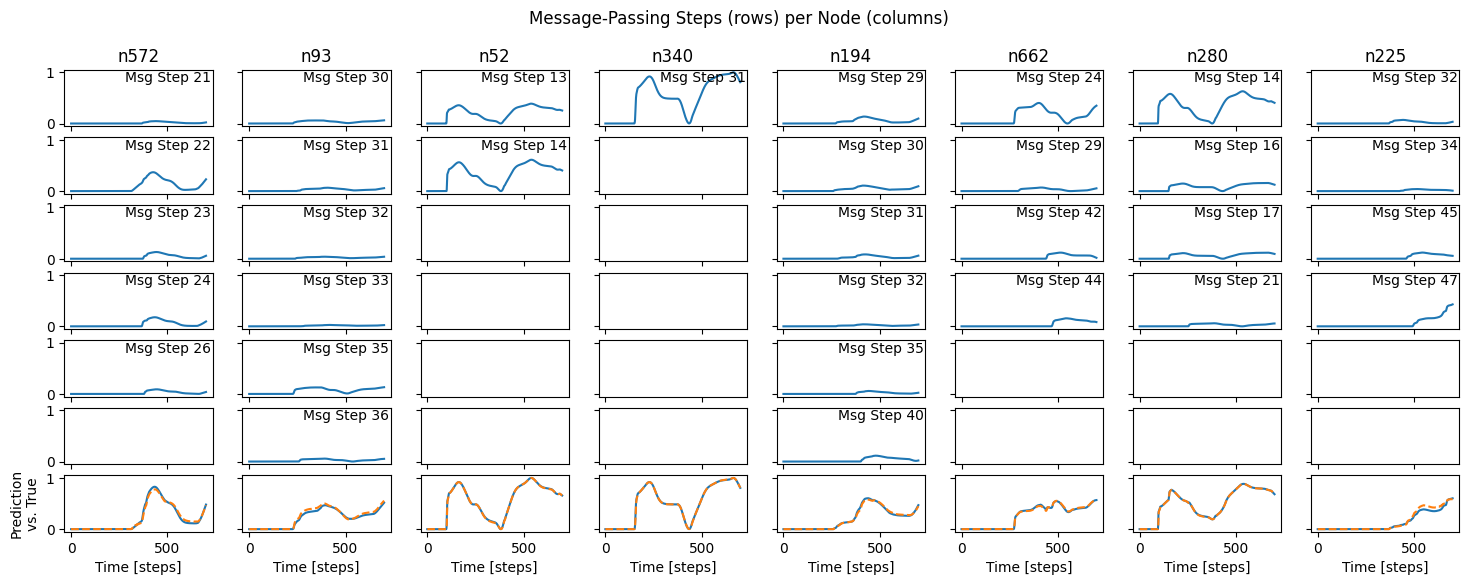

In [30]:
plot_some_nodes = [43, 66, 140, 230]
plot_some_nodes = [*np.random.RandomState(32).choice(len(aggs_all[0]), size=8, replace=False)]

n_msg_passing_steps = 6
fig, ax = plt.subplots(n_msg_passing_steps+1, len(plot_some_nodes), sharex=True, sharey=True, figsize=(18, n_msg_passing_steps))
fig.suptitle('Message-Passing Steps (rows) per Node (columns)')
axit = iter(ax.T.flat)

node_names = np.array(topo.get_all_nodes())[plot_some_nodes]

for _n, n in enumerate(plot_some_nodes):
    nstep = n_msg_passing_steps
    ax[0, _n].set_title(node_names[_n])
    
    for i in range(len(aggs_all)):
        if aggs_all[i][n].mean() > 0.01 and nstep > 0:
            _ax = ax[n_msg_passing_steps-nstep, _n]
            _ax.plot(aggs_all[i][n].cpu())
            _ax.text(0.99, 0.98, f'Msg Step {i}', transform=_ax.transAxes, va='top', ha='right')
            nstep -= 1
        
    _ax = ax[-1, _n]
    _ax.plot(pred[n], color='C0')
    _ax.plot(gt_data[n,:cT+Tau], color='C1', linestyle='--')
    _ax.set_xlabel('Time [steps]')
    
    if _n == 0:
        _ax.set_ylabel('Prediction\nvs. True')